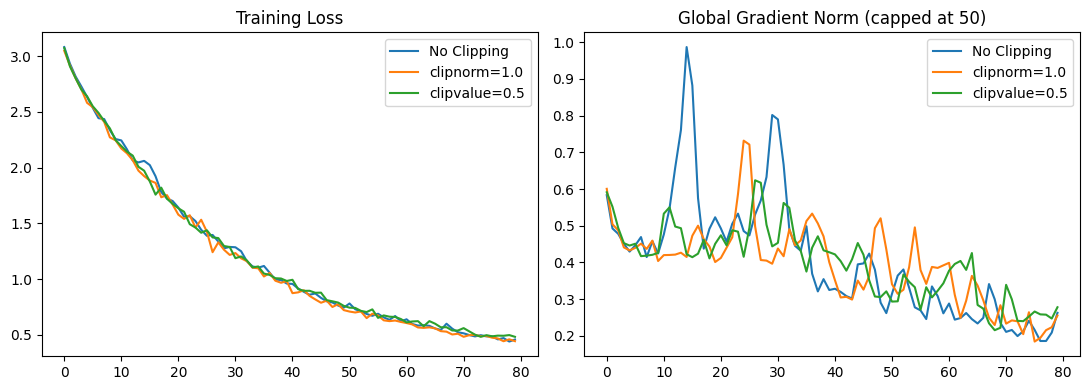

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

text = list("hello deep learning world! gradient clipping prevents exploding gradients. " * 40)
chars = sorted(set(text))
c2i = {c: i for i, c in enumerate(chars)}
seq_len = 15
X_idx = np.array([[c2i[c] for c in text[i:i+seq_len]] for i in range(len(text) - seq_len - 1)])
Y_idx = np.array([[c2i[c] for c in text[i+1:i+seq_len+1]] for i in range(len(text) - seq_len - 1)])
X_oh = tf.one_hot(X_idx, len(chars))

def run_training(clip_type=None, thresh=1.0):
    cell = tf.keras.layers.SimpleRNNCell(32)
    head = tf.keras.layers.Dense(len(chars))
    opt = tf.keras.optimizers.SGD(learning_rate=0.5)
    losses, gnorms = [], []
    for step in range(80):
        idx = np.random.randint(0, len(X_oh), 32)
        xb = tf.gather(X_oh, idx)
        yb = Y_idx[idx]
        with tf.GradientTape() as tape:
            h = tf.zeros((32, 32))
            logits = []
            for t in range(seq_len):
                h, _ = cell(xb[:, t, :], [h])
                logits.append(head(h))
            logits = tf.stack(logits, axis=1)
            loss = tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(yb, logits, from_logits=True))
        vars_ = cell.trainable_weights + head.trainable_weights
        grads = tape.gradient(loss, vars_)
        gnorm = float(tf.linalg.global_norm(grads))
        if clip_type == "norm":
            grads, _ = tf.clip_by_global_norm(grads, thresh)
        elif clip_type == "value":
            grads = [tf.clip_by_value(g, -thresh, thresh) for g in grads]
        opt.apply_gradients(zip(grads, vars_))
        losses.append(float(loss))
        gnorms.append(gnorm)
    return losses, gnorms

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, cfg in [("No Clipping", (None, 0)), ("clipnorm=1.0", ("norm", 1.0)), ("clipvalue=0.5", ("value", 0.5))]:
    l, g = run_training(*cfg)
    axes[0].plot(l, label=label)
    axes[1].plot(np.clip(g, 0, 50), label=label)
axes[0].set_title("Training Loss")
axes[0].legend()
axes[1].set_title("Global Gradient Norm (capped at 50)")
axes[1].legend()
plt.tight_layout()
plt.show()